In [1]:
try:
    from pytorch_tabnet.tab_model import TabNetClassifier
except:
    !uv pip install -q pytorch-tabnet
    from pytorch_tabnet.tab_model import TabNetClassifier

try:
    import skrub
except:
    !uv pip install -q skrub
    import skrub

In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

# %load_ext cuml.accel
# %load_ext cudf.pandas

'GPU: Tesla T4'

In [3]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [5]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import gc
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, TargetEncoder as skTE

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [6]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

Train shape: (699635, 23)
Test shape: (299844, 22)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>


In [8]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [9]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [10]:
ID = 'id'
TARGET = 'satisfaction'
train[TARGET] = train[TARGET].map({False: 0, True: 1})
X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]
del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('Class', 'Type of Travel', 'Gender'),
    ('Class', 'Type of Travel', 'Age'),
    ('Flight Distance', 'Departure/Arrival time convenient'),
]
def feature_engineering(df, fit=False):
    # Fill NaNs
    for col in cat_cols:
        df[col] = df[col].fillna("missing").factorize()[0]
    for col in num_cols:
        df[col] = df[col].fillna(0.0)

    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Count encoding
    for col in cat_cols + ['Leg room service']:
        count_name = f"_{col}_count"
        if fit:
            count_map = df[col].value_counts()
            category_map[count_name] = count_map
        else:
            count_map = category_map[count_name]
        df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699635, 21)
X_test init shape: (299844, 21) 

init len(cat_cols): 4
init len(num_cols): 17 

len(new_cat_cols): 20
len(new_num_cols): 5 

prep len(cat_cols): 24
prep len(num_cols): 22 

X      prep shape: (699635, 46)
X_test prep shape: (299844, 46) 



In [11]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    pd.concat([X, y], axis=1),
    train_size=100_000,
    stratify=y,
    random_state=42,
)

train_X = pd.concat([X, y], axis=1) if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699635, 47) <class 'pandas.core.frame.DataFrame'>


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,Class_Type of Travel_Age_,Flight Distance_Departure/Arrival time convenient_,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,347952,576990,202194,327404,204124,0,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,351683,576990,497441,342212,182369,1,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,347952,576990,202194,327404,131580,0,2,2,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,351683,576990,202194,327404,182369,2,3,3,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,347952,122645,497441,327404,204124,3,4,4,0


In [12]:
# ## -- Handle optional original table aggregations --
# USE_ORIGINAL = True

# import_cols  = ['Flight Distance', 'Age'] + cat_cols + service_cols

# if USE_ORIGINAL:
#     aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique",
#     feats = FEATURES.copy()
#     x_train, orig_cols = original_TE(
#         orig, train_X, target=TARGET, features = import_cols,
#         aggs=aggs_, fill_nan=True
#     )
#     x_test, _ = original_TE(
#         orig, test, target=TARGET, features = import_cols,
#         aggs=aggs_, fill_nan=True
#     )
#     feats.extend(orig_cols)
#     X = x_train[feats]
#     X_test = x_test[feats]
#     y = train_X[TARGET].astype("int32")
# else:
#     X = train_X[FEATURES]
#     X_test = test[FEATURES]
#     y = train_X[TARGET].astype("int32")

# print(X.shape, type(X))
# # X.head()

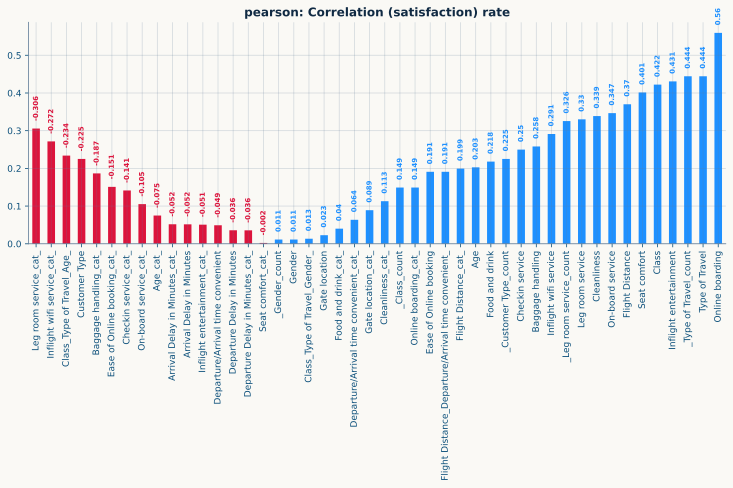

In [13]:
corr_type = ['pearson', 'spearman'][0]

df = X.copy()
for c in df.columns:
    if df[c].dtype in ['object', 'category']:
        # errors='coerce' turns non-numeric text into NaN instead of crashing
        df[c] = pd.factorize(df[c], sort=True)[0]
corr_df = df.corrwith(train_X[TARGET], method=corr_type).sort_values()

plt.figure(figsize=(12.5, 4))
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.02, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center', rotation=90,
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [14]:
# ## -- Reduce data memory --
# def reduce_memory(df):
#     old_size = df.memory_usage(deep=True).sum() / (1024*1024)
#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         if df[c].dtype == np.int64:
#             ## -- Downcast Integer type ---
#             if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
#                 df[c] = df[c].astype(np.int32)
#                 # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
#                 #     df[c] = df[c].astype(np.int16)
#                 #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
#                 #         df[c] = df[c].astype(np.int8)
#         elif df[c].dtype == np.float64:
#             ## -- Downcast Float type -----
#             if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
#                 df[c] = df[c].astype(np.float32)
#                 # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
#                 #     df[c] = df[c].astype(np.float16)

#     new_size = df.memory_usage(deep=True).sum() / (1024*1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f}MB\n")

#     return df

# X = reduce_memory(X)
# X_test = reduce_memory(X_test)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

In [15]:
X.dtypes

Age                                                      int64
Flight Distance                                          int64
Inflight wifi service                                    int64
Departure/Arrival time convenient                        int64
Ease of Online booking                                   int64
Gate location                                            int64
Food and drink                                           int64
Online boarding                                          int64
Seat comfort                                             int64
Inflight entertainment                                   int64
On-board service                                         int64
Leg room service                                         int64
Baggage handling                                         int64
Checkin service                                          int64
Cleanliness                                              int64
Departure Delay in Minutes                             

# ML TRAINING

In [16]:
core_params = {
    # 'n_steps': 3,
    # 'gamma': 1.3,
    # 'n_independent': 2,
    # 'n_shared': 2,
    # 'epsilon': 1e-15,
    # 'lambda_sparse': 1e-3,
    # 'cat_emb_dim': 2,
    # 'mask_type': 'sparsemax',
    # 'scheduler_fn': torch.optim.lr_scheduler.StepLR,
    # 'scheduler_params': {'step_size': 20, 'gamma': 0.9},
    'optimizer_fn': torch.optim.Adam,
    # 'optimizer_params': {'lr': 0.01, 'weight_decay': 0.0}, #⚠️ working with lr
    'device_name': "cuda", # 'auto
    'verbose': 1,
}

nd2_params = {'n_d': 2, 'n_a': 2} | core_params
nd4_params = {'n_d': 4, 'n_a': 4} | core_params
nd6_params = {'n_d': 6, 'n_a': 6} | core_params
nd8_params = {'n_d': 8, 'n_a': 8} | core_params

all_models = {
    'nd2': ('TABNETnd2_mlp', nd2_params),
    'nd4': ('TABNETnd4_mlp', nd4_params),
    'nd6': ('TABNETnd6_mlp', nd6_params),
    'nd8': ('TABNETnd8_mlp', nd8_params),
}

print("🤖 Model parameters defined!")
# all_models['bag']

🤖 Model parameters defined!


In [17]:
# full_df = pd.concat([X, X_test])
# for col in cat_cols:
#     l_enc = LabelEncoder()
#     l_enc.fit(full_df[col].astype(str))
#     X[col] = l_enc.transform(X[col].astype(str))
#     X_test[col] = l_enc.transform(X_test[col].astype(str))

# all_features = full_df.columns.tolist()
# cats_dict = { col: full_df[col].nunique() for col in all_cat_cols }

# cats_in_cols = [ f for f in all_cat_cols if f in all_features ]
# cat_idxs = [ all_features.index(f) for f in cats_in_cols ]
# cat_dims = [ cats_dict[f] for f in all_features if f in cats_in_cols ]

# print("cat_idxs:", cat_idxs)
# print("cat_dims:", cat_dims)

In [18]:
cat_cols

['Gender',
 'Customer Type',
 'Type of Travel',
 'Class',
 'Age_cat_',
 'Flight Distance_cat_',
 'Inflight wifi service_cat_',
 'Departure/Arrival time convenient_cat_',
 'Ease of Online booking_cat_',
 'Gate location_cat_',
 'Food and drink_cat_',
 'Online boarding_cat_',
 'Seat comfort_cat_',
 'Inflight entertainment_cat_',
 'On-board service_cat_',
 'Leg room service_cat_',
 'Baggage handling_cat_',
 'Checkin service_cat_',
 'Cleanliness_cat_',
 'Departure Delay in Minutes_cat_',
 'Arrival Delay in Minutes_cat_',
 'Class_Type of Travel_Gender_',
 'Class_Type of Travel_Age_',
 'Flight Distance_Departure/Arrival time convenient_']

In [19]:
X.columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'Age_cat_',
       'Flight Distance_cat_', 'Inflight wifi service_cat_',
       'Departure/Arrival time convenient_cat_', 'Ease of Online booking_cat_',
       'Gate location_cat_', 'Food and drink_cat_', 'Online boarding_cat_',
       'Seat comfort_cat_', 'Inflight entertainment_cat_',
       'On-board service_cat_', 'Leg room service_cat_',
       'Baggage handling_cat_', 'Checkin service_cat_', 'Cleanliness_cat_',
       'Departure Delay in Minutes_cat_', 'Arrival Delay in Minutes_cat_',
       '_Gender_count', '_Customer Type

In [20]:
class CFG:
    TE = True if 'combo_names' in globals() else False
    SCRUB = False
    METRIC = ['auc']
    FOLDS = 5
    SEED = 42
    BATCH = 2048//2 if torch.cuda.is_available() else 128
    EPOCH = 100
    ES = 5
    PREDICT_TEST = True

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'nd6' # 'nd2' 'nd4' 'nd6' 'nd8'
model_name = all_models[_id][0]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n🚀 Training {model_name} with {FOLDS } Folds | Device: {device}")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

cats_ = [c for c in cat_cols if c.endswith("_cat_")]
all_cats = cat_cols #+ cats_ # ⚠️

fold_scores = []
feat_masks  = []
feat_importances = []
best_iterations  = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    # Target encoding
    if CFG.TE:
        te_cols = combo_names # + cats_

        TE = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = [
            'Class_Type of Travel_Age_',
            'Flight Distance_Departure/Arrival time convenient_',
        ] #+ cats_
        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    all_cat_cols = [c for c in all_cats if c not in combos_to_drop]
    get_nums = X_tr.columns.difference(all_cat_cols, sort=False).tolist()

    scaler = StandardScaler()
    X_tr[get_nums]  = scaler.fit_transform(X_tr[get_nums])
    X_val[get_nums] = scaler.transform(X_val[get_nums])
    X_tst[get_nums] = scaler.transform(X_tst[get_nums])

    # qt = QuantileTransformer(output_distribution='normal', random_state=42)
    # X_tr_num    = qt.fit_transform(X_tr_num)
    # X_val_num   = qt.transform(X_val_num)
    # X_test_num  = qt.transform(X_test_num)

    seeder = 42 # + (idx-1)
    params = all_models[_id][1].copy()
    params.update({
        'optimizer_params': {'lr': 0.01, 'weight_decay': 0.0},
        'seed': seeder,
    })

    # --------------------------------------------------------------------------
    if CFG.SCRUB:
        print("Skrub processor")
        tabvec = skrub.TableVectorizer(n_jobs=-1)
        X_tr  = tabvec.fit_transform(X_tr, y_tr)
        X_val = tabvec.transform(X_val)
        X_tst = tabvec.transform(X_tst)

        model = TabNetClassifier(**params)
    else:
        ## -- Define cat features for cat embeddings --
        print("TabNet embedding processor")
        full_df = pd.concat([X_tr, X_val, X_tst])
        for col in all_cat_cols:
            l_enc = LabelEncoder()
            l_enc.fit(full_df[col].astype(str))
            X_tr[col]  = l_enc.transform(X_tr[col].astype(str))
            X_val[col] = l_enc.transform(X_val[col].astype(str))
            X_tst[col] = l_enc.transform(X_tst[col].astype(str))

        all_features = full_df.columns.tolist()
        cats_dict = { col: full_df[col].nunique() for col in all_cat_cols }

        cats_in_cols = [ f for f in all_cat_cols if f in all_features ]
        cat_idxs = [ all_features.index(f) for f in cats_in_cols ]
        cat_dims = [ cats_dict[f] for f in all_features if f in cats_in_cols ]
        if fold == 1:
            print("cat_idxs:", cat_idxs)
            print("cat_dims:", cat_dims)
            display(X_tr.head(3))

        model = TabNetClassifier(**params) #, cat_idxs=cat_idxs, cat_dims=cat_dims)

    print("-"*30)
    print(f"Epochs={CFG.EPOCH} | Early_Stop={CFG.ES}")
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}")
    print("-"*30)

    model.fit(
        X_tr.to_numpy(), y_tr.values,
        eval_set=[(X_tr.to_numpy(), y_tr.values), (X_val.values, y_val.values)],
        max_epochs=CFG.EPOCH, # 200
        patience=CFG.ES, # 10
        eval_metric=CFG.METRIC,
        # weights=get_sample_weights(y_train, y_train),
        # batch_size=2048,
        # virtual_batch_size=512,
        drop_last=False,
    )
    feat_importances.append(model.feature_importances_)
    # ------------------------------------------------------------------------------
    ## -- Predict on validation and test sets --
    print("-"*30)
    p0 = time()

    val_preds = model.predict_proba(X_val.to_numpy())[:, 1]
    p1 = time()
    print(f"⧗ val prediction time: {p1-p0:.2f} secs")
    oof_preds[val_idx] = val_preds

    if CFG.PREDICT_TEST:
        p0 = time()
        fold_test_preds = model.predict_proba(X_tst.to_numpy())[:, 1]
        test_preds += fold_test_preds
        p1 = time()
        print(f"⧗ tst prediction time: {p1-p0:.2f} secs")

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    ## -- Get mask/evalute data --
    _, mask = model.explain(X_val.to_numpy())
    feat_masks.append(mask)

    best_iter = model.best_epoch
    best_iterations.append(best_iter)

    print("-"*30)
    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, best_epoch={best_iter}\n")
    torch.cuda.empty_cache()

test_preds /= FOLDS

features_used = X_tr.columns
model_name = model_name + f"({len(features_used)})"

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_tr, X_val, y_tr, y_val, model


🚀 Training TABNETnd6_mlp with 5 Folds | Device: cuda
### Fold 1/5
TabNet embedding processor
cat_idxs: [17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 43]
cat_dims: [2, 2, 2, 3, 75, 3475, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 6, 6, 168, 169, 12]


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,TE_Class_Type of Travel_Gender_,TE_Class_Type of Travel_Age_,TE_Flight Distance_Departure/Arrival time convenient_
0,-0.217432,-0.691763,0.953607,0.571009,0.892062,-0.011209,-1.743707,0.492951,-2.015410,-1.876702,-0.417857,0.413472,0.179991,-0.347026,-1.863996,-0.195866,-0.196398,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,-1.006384,0.460951,-1.568993,0.088183,1.017586,0,-1.213232,-1.163909,-0.693403
1,1.231292,-0.736822,1.734427,1.248735,1.644105,1.583693,1.333407,0.492951,0.337866,1.182312,1.197523,1.200390,1.106827,0.478911,-0.298269,-0.195866,-0.196398,1,0,1,1,1,2,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0.993656,0.460951,0.637351,0.326439,0.527860,1,1.025257,1.334207,0.022189
3,-2.100774,0.274390,0.172788,1.248735,0.140019,-0.011209,-0.205150,-0.282805,-0.446560,-0.347195,0.389833,1.200390,-0.746845,0.478911,-0.298269,-0.195866,-0.196398,1,0,0,0,23,2224,2,1,3,0,2,1,2,2,2,1,2,1,1,1,1,0.993656,0.460951,-1.568993,0.088183,0.527860,4,-1.204846,-1.153722,0.120294


------------------------------
Epochs=100 | Early_Stop=5
train=(559708, 47), valid=(139927, 47)
------------------------------
epoch 0  | loss: 0.31914 | val_0_auc: 0.94718 | val_1_auc: 0.94691 |  0:00:36s
epoch 1  | loss: 0.26748 | val_0_auc: 0.95016 | val_1_auc: 0.95086 |  0:01:12s
epoch 2  | loss: 0.25742 | val_0_auc: 0.95181 | val_1_auc: 0.95175 |  0:01:48s
epoch 3  | loss: 0.25219 | val_0_auc: 0.95263 | val_1_auc: 0.9528  |  0:02:23s
epoch 4  | loss: 0.24707 | val_0_auc: 0.95361 | val_1_auc: 0.95361 |  0:02:59s
epoch 5  | loss: 0.24556 | val_0_auc: 0.95396 | val_1_auc: 0.95376 |  0:03:35s
epoch 6  | loss: 0.24209 | val_0_auc: 0.95487 | val_1_auc: 0.95458 |  0:04:11s
epoch 7  | loss: 0.24145 | val_0_auc: 0.95528 | val_1_auc: 0.95489 |  0:04:47s
epoch 8  | loss: 0.23912 | val_0_auc: 0.95596 | val_1_auc: 0.9555  |  0:05:22s
epoch 9  | loss: 0.23844 | val_0_auc: 0.95613 | val_1_auc: 0.95602 |  0:05:59s
epoch 10 | loss: 0.23764 | val_0_auc: 0.95637 | val_1_auc: 0.95588 |  0:06:35s
epoc

In [21]:
# ==================================================
# 5-FOLD CV: TABNETnd2_se(21) | (559708, 21)
# ==================================================
#  • Fold 1 AUC: 0.952349 @ tree 9
#  • Fold 2 AUC: 0.953324 @ tree 8
#  • Fold 3 AUC: 0.953832 @ tree 5
#  • Fold 4 AUC: 0.953353 @ tree 9
#  • Fold 5 AUC: 0.953365 @ tree 7
# --------------------------------------------------
# OOF score: 0.953193
# AVG score: 0.953245 ± 0.000486
# --------------------------------------------------
# 32.31 mins

In [22]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.957882
fold_2  0.956728
fold_3  0.957492
fold_4  0.957476
fold_5  0.958163
-------------------------
TABNETnd6_mlp(47)_957548
-------------------------
94.89 mins


In [23]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.233605
1,699636,0.813127
2,699637,0.312415
3,699638,0.034705
4,699639,0.034796
...,...,...
299839,999474,0.035418
299840,999475,0.035553
299841,999476,0.216810
299842,999477,0.037080


In [24]:
# !rm -r /kaggle/working

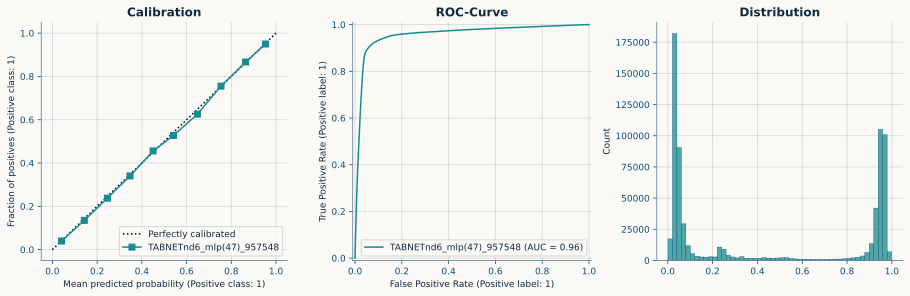

In [25]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

Total used features: 47



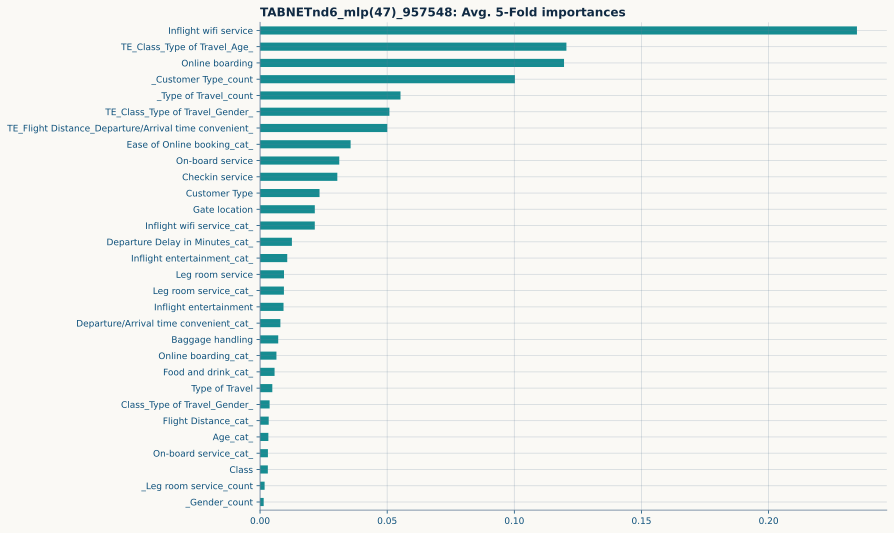

In [26]:
## -- Feature Importances --
top_n = 30

imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()[-top_n:]
print(f"Total used features: {len(features_used)}\n")

ax = imp_df.plot.barh(figsize=(12.5, len(imp_df)*0.25))
ax.set_title(f"{n}: Avg. {FOLDS}-Fold importances", loc='left')
ax.grid(True)

plt.tight_layout()
plt.show()

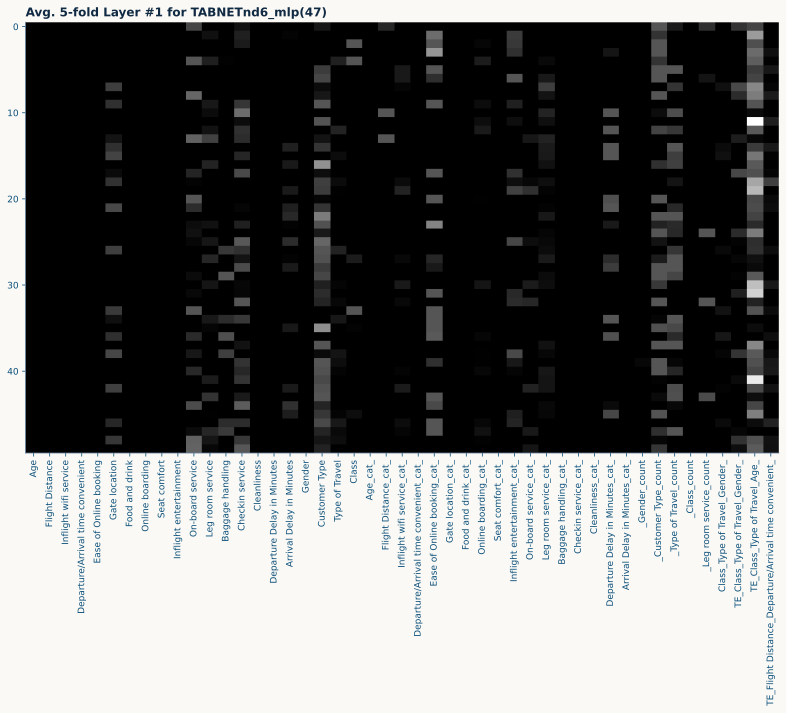

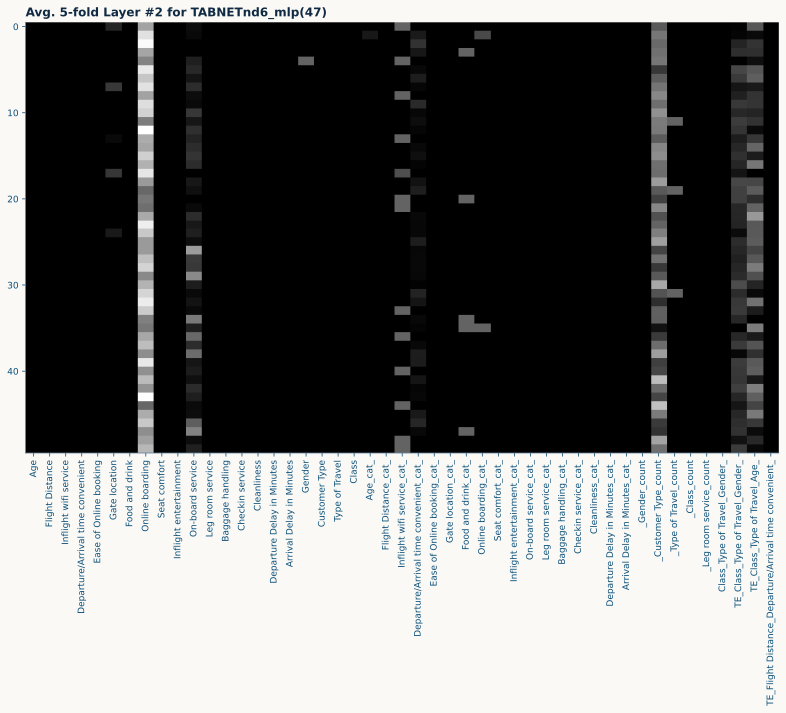

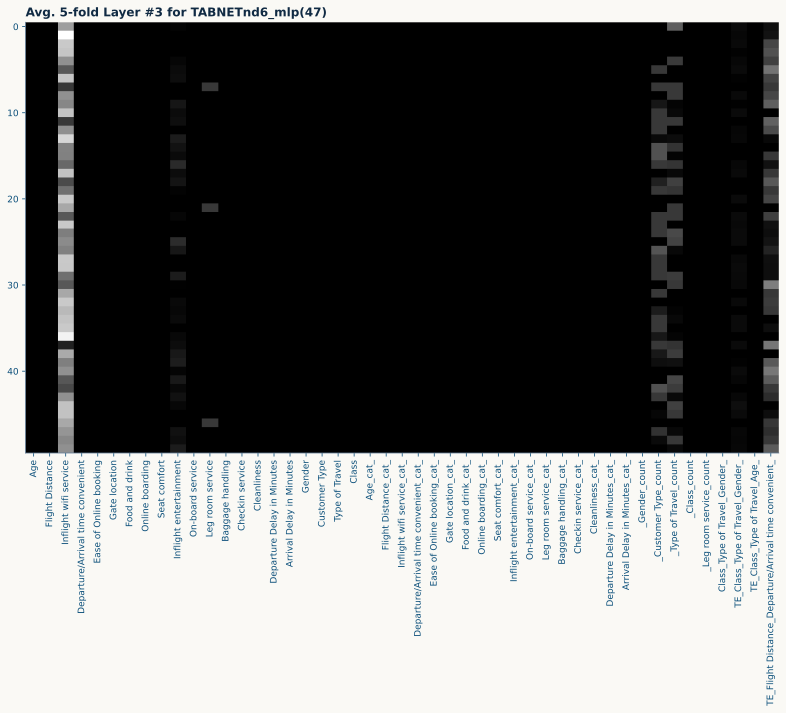

In [27]:
sample_ = 50
for i in range(3):
    fig, ax = plt.subplots(1, 1, figsize=(11, 10))

    data_ = np.sum(
        (
            feat_masks[0][i][:sample_],
            feat_masks[1][i][:sample_],
            feat_masks[2][i][:sample_],
            feat_masks[3][i][:sample_],
            feat_masks[4][i][:sample_],
        ),
        axis=0,
    ) / FOLDS
    ax.imshow(data_, cmap='gray', aspect='auto')
    ax.set_title(f"Avg. {FOLDS}-fold Layer #{i+1} for {model_name}", loc='left')
    ax.set_xticks(range(len(features_used)), features_used)
    ax.tick_params('x', rotation=90)
    ax.grid()
    plt.tight_layout()
    plt.show()
    print()